In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
from sklearn.impute import KNNImputer

pio.renderers.default = "png"

data_path_1 = r'datasets/Titanic.csv'   
data_path_2 = r'datasets/sendy_logistics.csv'   
data_path_3 = r'datasets/ufo.csv'

# - Titanic handling missing values

In [2]:
# Load Data
df = pd.read_csv(data_path_1)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Check missing valyes by ( Count & Percentage)

print('Missing value per Column\n',df.isna().sum())

missing_values = pd.DataFrame(
    {
        'Count' : df.isna().sum(), 
        'Percent' : df.isna().mean() * 100
    })
missing_values[missing_values['Count'] > 0].sort_values(by= 'Count', ascending= False).round(2)

Missing value per Column
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


,Count,Percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


In [4]:
# Drop col `Cabin` ~~>> (77.10 %) Nan

df.drop('Cabin', axis= 1, inplace= True)

In [5]:
# Drop missing values raws in `Embarked` ~~>> (.22 %) Nan

df.dropna(subset= 'Embarked', inplace= True, ignore_index= True )

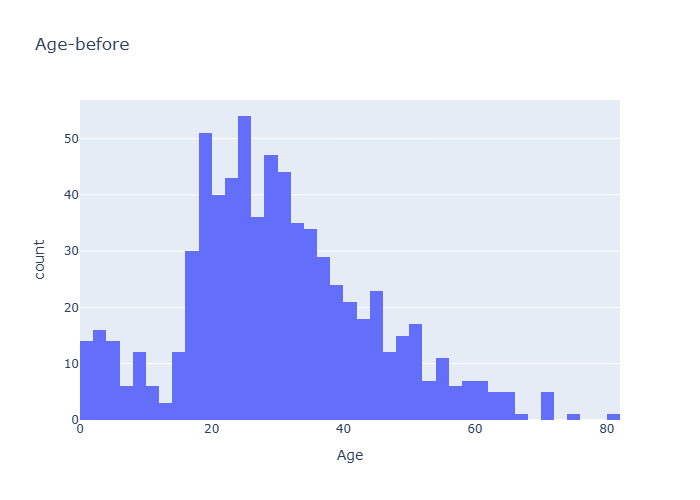

In [6]:
# Col `Age` (Discrete) fill NaN with median value based on Sex(Male - Female) & Pclass ~~>> (19.91 %)

px.histogram(data_frame= df, x= 'Age', title= 'Age-before')

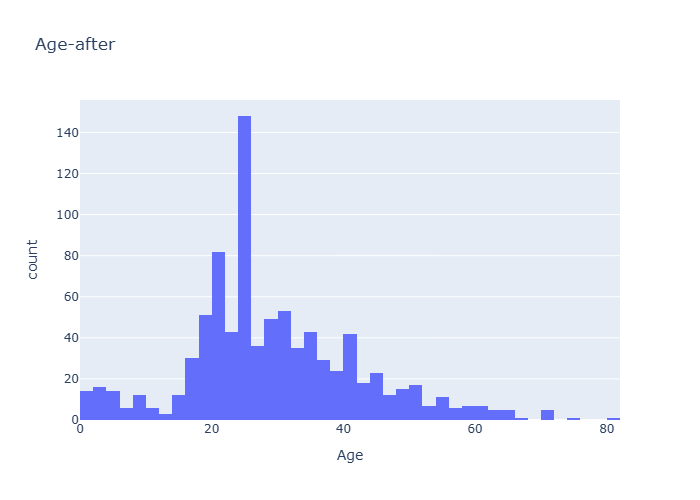

In [7]:
df['Age'] = df.groupby(['Sex', 'Pclass'])['Age'].transform(lambda s: s.fillna(s.median()))
px.histogram(df, x='Age', title='Age-after')

# - Sendy-logistics handling missing values

In [8]:
# Load Data

df = pd.read_csv(data_path_2)
df.head()

,Order No,User Id,Vehicle Type,Platform Type,Personal or Business,Placement - Day of Month,Placement - Weekday (Mo = 1),Placement - Time,Confirmation - Day of Month,Confirmation - Weekday (Mo = 1),...,Arrival at Destination - Time,Distance (KM),Temperature,Precipitation in millimeters,Pickup Lat,Pickup Long,Destination Lat,Destination Long,Rider Id,Time from Pickup to Arrival
0,Order_No_4211,User_Id_633,Bike,3,Business,9,5,9:35:46 AM,9,5,...,10:39:55 AM,4,20.4,NaN,-1.317755,36.830370,-1.300406,36.829741,Rider_Id_432,745
1,Order_No_25375,User_Id_2285,Bike,3,Personal,12,5,11:16:16 AM,12,5,...,12:17:22 PM,16,26.4,NaN,-1.351453,36.899315,-1.295004,36.814358,Rider_Id_856,1993
2,Order_No_1899,User_Id_265,Bike,3,Business,30,2,12:39:25 PM,30,2,...,1:00:38 PM,3,NaN,NaN,-1.308284,36.843419,-1.300921,36.828195,Rider_Id_155,455
3,Order_No_9336,User_Id_1402,Bike,3,Business,15,5,9:25:34 AM,15,5,...,10:05:27 AM,9,19.2,NaN,-1.281301,36.832396,-1.257147,36.795063,Rider_Id_855,1341
4,Order_No_27883,User_Id_1737,Bike,1,Personal,13,1,9:55:18 AM,13,1,...,10:25:37 AM,9,15.4,NaN,-1.266597,36.792118,-1.295041,36.809817,Rider_Id_770,1214


In [9]:
# Check missing valyes by ( Count & Percentage)

print('Missing value per Column\n', df.isna().sum())

missing_values = pd.DataFrame(
    {
        'Count' : df.isna().sum(), 
        'Percent' : df.isna().mean() * 100
    })
missing_values[missing_values['Count'] > 0].sort_values(by= 'Count', ascending= False).round(2)

Missing value per Column
 Order No                                         0
User Id                                          0
Vehicle Type                                     0
Platform Type                                    0
Personal or Business                             0
Placement - Day of Month                         0
Placement - Weekday (Mo = 1)                     0
Placement - Time                                 0
Confirmation - Day of Month                      0
Confirmation - Weekday (Mo = 1)                  0
Confirmation - Time                              0
Arrival at Pickup - Day of Month                 0
Arrival at Pickup - Weekday (Mo = 1)             0
Arrival at Pickup - Time                         0
Pickup - Day of Month                            0
Pickup - Weekday (Mo = 1)                        0
Pickup - Time                                    0
Arrival at Destination - Day of Month            0
Arrival at Destination - Weekday (Mo = 1)        0
Arriv

,Count,Percent
Precipitation in millimeters,20649,97.40
Temperature,4366,20.59


In [10]:
# Drop col `Precipitation in millimeters` ~~>>  ( 97.40% ) Nan

df.drop('Precipitation in millimeters', axis= 1, inplace= True) 

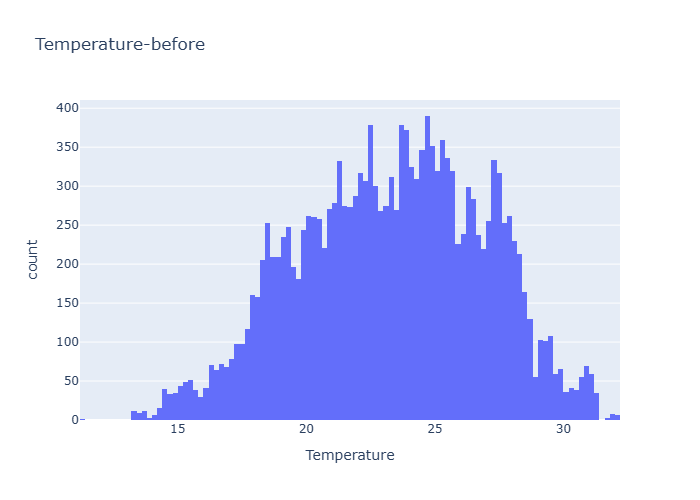

In [11]:
# Col `Temperature` (Continus) fill NaN with temperature knn-imputer value ~~>> ( 20.59%) NaN

px.histogram(df, x= 'Temperature', title= 'Temperature-before')

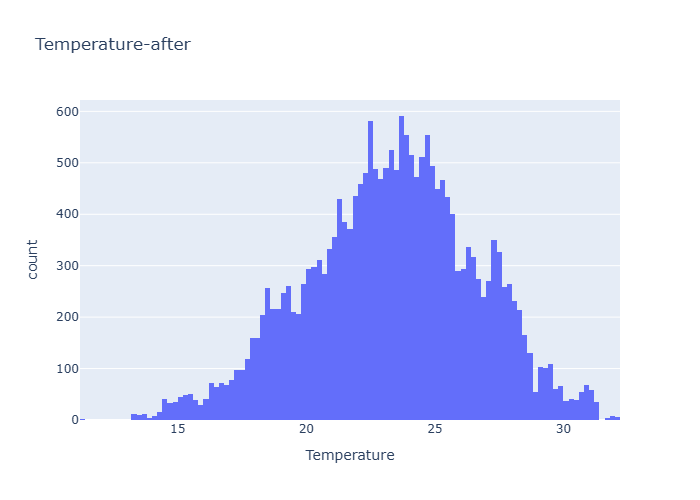

In [12]:
num_colum = df.select_dtypes(include= 'number').columns
knn = KNNImputer(n_neighbors= 5)
df[num_colum] = knn.fit_transform(df[num_colum])
px.histogram(data_frame= df, x= 'Temperature', title='Temperature-after')

# - UFO handling missing values 

In [13]:
# Load Data

df = pd.read_csv(data_path_3)
df.head()

,City,Colors Reported,Shape Reported,State,Time
0,Ithaca,NaN,TRIANGLE,NY,6/1/1930 22:00
1,Willingboro,NaN,OTHER,NJ,6/30/1930 20:00
2,Holyoke,NaN,OVAL,CO,2/15/1931 14:00
3,Abilene,NaN,DISK,KS,6/1/1931 13:00
4,New York Worlds Fair,NaN,LIGHT,NY,4/18/1933 19:00


In [14]:
# Check missing valyes by ( Count & Percentage)

print('Missing value per Column\n', df.isna().sum())

missing_values = pd.DataFrame(
    {
        'Count' : df.isna().sum(), 
        'Percent' : df.isna().mean() * 100
    })
missing_values[missing_values['Count'] > 0].sort_values(by= 'Count', ascending= False).round(2)

Missing value per Column
 City                  26
Colors Reported    15359
Shape Reported      2644
State                  0
Time                   0
dtype: int64


,Count,Percent
Colors Reported,15359,84.20
Shape Reported,2644,14.49
City,26,0.14


In [15]:
# Drop col `Colors Reported` ~~>> ( 84.20% ) NaN

df.drop('Colors Reported', axis= 1, inplace= True)

In [16]:
# Col `Shape Reported` fill NaN with 'OTHER' ~~>> ( 14.49% )

df['Shape Reported'] = df['Shape Reported'].fillna('OTHER')

In [17]:
# Col `City` fill NaN with mode-of-city ~~>> ( 0.14% )

city_mode = df['City'].mode()[0]
df['City'] = df['City'].fillna(city_mode)